# Phase 3: The peeking problem
**Question:** what happens if a team checks results as data arrives and stops at the first significant read?

In [1]:
import pandas as pd
import numpy as np
from scipy import stats

In [2]:
df = pd.read_csv('cookie_cats.csv')

In [3]:
metric = 'retention_7'
checkpoints_frac = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

In [4]:
def run_one_simulation(seed):
    rng = np.random.default_rng(seed)
    shuffled = df.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    n_total = len(shuffled)
    pvals = []
    diffs = []
    for frac in checkpoints_frac:
        n_cut = int(n_total*frac)
        sub = shuffled.iloc[:n_cut]
        g30 = sub[sub['version']=='gate_30'][metric].astype(int)
        g40 = sub[sub['version']=='gate_40'][metric].astype(int)
        if len(g30) < 30 or len(g40) < 30:
            pvals.append(np.nan); diffs.append(np.nan); continue
        p30, p40 = g30.mean(), g40.mean()
        count = np.array([g30.sum(), g40.sum()])
        nobs = np.array([len(g30), len(g40)])
        p_pool = count.sum()/nobs.sum()
        se = np.sqrt(p_pool*(1-p_pool)*(1/nobs[0] + 1/nobs[1]))
        z = (p30-p40)/se if se>0 else 0
        p_val = 2*(1-stats.norm.cdf(abs(z)))
        pvals.append(p_val)
        diffs.append(p30-p40)
    return pvals, diffs

n_sims = 20
all_pvals = []
first_sig_checkpoint = []
final_sig = []

for seed in range(n_sims):
    pvals, diffs = run_one_simulation(seed)
    all_pvals.append(pvals)
    sig_idx = next((i for i,p in enumerate(pvals) if not np.isnan(p) and p<0.05), None)
    first_sig_checkpoint.append(checkpoints_frac[sig_idx] if sig_idx is not None else None)
    final_sig.append(pvals[-1] < 0.05)

all_pvals = np.array(all_pvals)

print("Median p-value trajectory across 20 random arrival-order simulations:")
for i, frac in enumerate(checkpoints_frac):
    med_p = np.nanmedian(all_pvals[:,i])
    pct_sig = np.mean(all_pvals[:,i] < 0.05)*100
    print(f"  at {frac*100:>3.0f}% of sample (n~{int(len(df)*frac):>6}):  median p={med_p:.4f}   |   {pct_sig:.0f}% of runs already 'significant'")

n_would_stop_early_wrong = sum(1 for c in first_sig_checkpoint if c is not None and c < 1.0)
n_final_sig = sum(final_sig)
print(f"\nOf {n_sims} simulated arrival orders:")
print(f"  - {n_final_sig}/{n_sims} runs are significant (p<0.05) at the FULL sample")
print(f"  - {n_would_stop_early_wrong}/{n_sims} runs crossed p<0.05 at some point BEFORE 100% of the sample")
early_flips = sum(1 for i,c in enumerate(first_sig_checkpoint) if c is not None and c < 1.0 and not final_sig[i])
print(f"  - {early_flips}/{n_sims} runs would have shown 'significant' early and then it did NOT hold at the full sample size")

Median p-value trajectory across 20 random arrival-order simulations:
  at   5% of sample (n~  4509):  median p=0.3646   |   10% of runs already 'significant'
  at  10% of sample (n~  9018):  median p=0.5260   |   0% of runs already 'significant'
  at  20% of sample (n~ 18037):  median p=0.2556   |   10% of runs already 'significant'
  at  30% of sample (n~ 27056):  median p=0.0847   |   35% of runs already 'significant'
  at  40% of sample (n~ 36075):  median p=0.0286   |   60% of runs already 'significant'
  at  50% of sample (n~ 45094):  median p=0.0208   |   75% of runs already 'significant'
  at  60% of sample (n~ 54113):  median p=0.0153   |   75% of runs already 'significant'
  at  70% of sample (n~ 63132):  median p=0.0119   |   90% of runs already 'significant'
  at  80% of sample (n~ 72151):  median p=0.0036   |   100% of runs already 'significant'
  at  90% of sample (n~ 81170):  median p=0.0026   |   100% of runs already 'significant'
  at 100% of sample (n~ 90189):  median

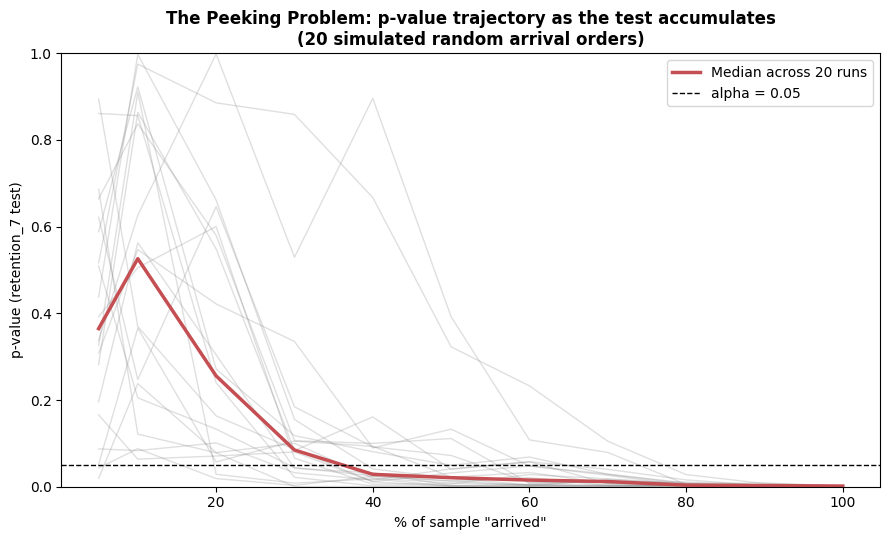

In [5]:
import matplotlib.pyplot as plt

checkpoints = np.array(checkpoints_frac) * 100
fig, ax = plt.subplots(figsize=(9, 5.5))
for i in range(all_pvals.shape[0]):
    ax.plot(checkpoints, all_pvals[i], color='grey', alpha=0.25, linewidth=1)
ax.plot(checkpoints, np.nanmedian(all_pvals, axis=0), color='#C44E52', linewidth=2.5,
        label=f'Median across {all_pvals.shape[0]} runs')
ax.axhline(0.05, color='black', linestyle='--', linewidth=1, label='alpha = 0.05')
ax.set_xlabel('% of sample "arrived"')
ax.set_ylabel('p-value (retention_7 test)')
ax.set_title(f'The Peeking Problem: p-value trajectory as the test accumulates\n({all_pvals.shape[0]} simulated random arrival orders)',
             fontsize=12, fontweight='bold')
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.savefig('chart2_peeking_trajectory.png', dpi=150, bbox_inches='tight')
plt.show()